# Where the rain went

*A decade of rainfall in Millbrook, and what the averages hide.*

Every autumn the same conversation starts at the bakery on Mill Street: *it rains less than it used to.* Nobody quite agrees on when it started, and nobody has looked at the numbers. This essay does. It uses ten years of monthly totals from the town's weather station, from January 2015 to December 2024, and asks a modest question: did Millbrook get drier, or did the rain only change its timing?

## The record

The station logs one number per month: the total rainfall in millimetres. Three things make the record easy to misread:

- a wet year can hide two dry seasons inside it,
- a single storm can carry a fifth of a month's total,
- the station moved 400 metres uphill in 2019.

We load the totals first and keep them in one tidy table.

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(7)
months = pd.date_range("2015-01-01", "2024-12-01", freq="MS")
season = 62 + 38 * np.cos((months.month - 1) / 12 * 2 * np.pi)
drift = np.linspace(0, -9, len(months)) * (months.month.isin([6, 7, 8]))
rain = pd.Series(np.clip(season + drift + rng.gamma(2.0, 9.0, len(months)) - 18, 4, None),
                 index=months, name="rain_mm").round(1)

yearly = rain.groupby(rain.index.year).sum().round()
yearly.to_frame("total (mm)").T

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
total (mm),670.0,718.0,690.0,757.0,702.0,695.0,666.0,684.0,766.0,643.0


## Totals barely move

Year by year, the totals wander within a band of about a hundred millimetres. There is no clean downward line. If the bakery is right, the change must hide in the seasons, not in the sum.

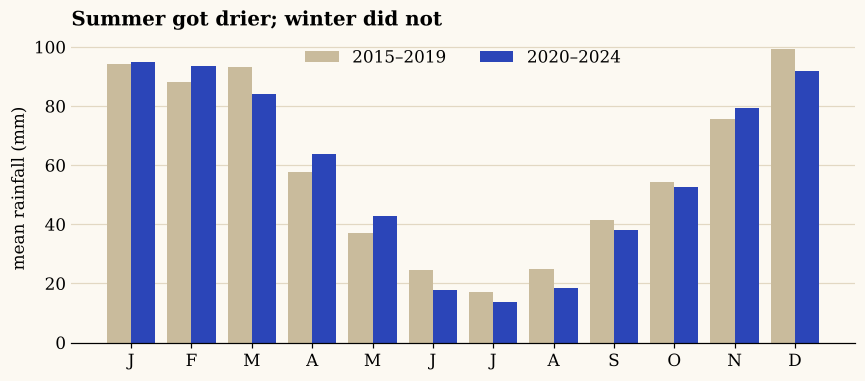

In [2]:
import matplotlib.pyplot as plt

early = rain[rain.index.year <= 2019].groupby(lambda d: d.month).mean()
late = rain[rain.index.year >= 2020].groupby(lambda d: d.month).mean()
labels = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

plt.rcParams.update({"font.family": "serif", "font.size": 11})
fig, ax = plt.subplots(figsize=(8, 3.6), dpi=110, facecolor="#fcf9f2")
ax.set_facecolor("#fcf9f2")
x = np.arange(12)
ax.bar(x - 0.2, early.values, width=0.4, color="#c9bb9c", label="2015–2019")
ax.bar(x + 0.2, late.values, width=0.4, color="#2b45b8", label="2020–2024")
ax.set_xticks(x, labels)
ax.set_ylabel("mean rainfall (mm)")
ax.set_title("Summer got drier; winter did not", loc="left", fontsize=13, fontweight="bold")
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", color="#e2d8c3", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", ncol=2)
fig.tight_layout()
plt.show()

## The summers moved

Split the decade in two halves and the picture changes. June, July and August lost a noticeable share of their rain in the second half, while the winter months held steady or grew. The total stays the same because the rain arrives later, in fewer and heavier storms.

> The town did not get drier. Its summers did, and summers are what people remember.

That difference matters for gardens, for the reservoir and for the bakery queue: a dry July feels like a dry year.

In [3]:
summer = rain[rain.index.month.isin([6, 7, 8])]
change = summer.groupby(summer.index.year >= 2020).mean()
print(f"Summer mean, 2015-2019: {change[False]:.1f} mm")
print(f"Summer mean, 2020-2024: {change[True]:.1f} mm")
print(f"Change: {100 * (change[True] / change[False] - 1):+.0f} %")

Summer mean, 2015-2019: 22.2 mm
Summer mean, 2020-2024: 16.7 mm
Change: -25 %


## What we can and cannot say

Ten years is a short record, and the station moved halfway through it. The pattern is suggestive, not proof. The next step is to compare with the two neighbouring stations, which did not move, before anyone writes to the council about the reservoir.